## Libraries

In [25]:
#Data manipulation
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Merge the csv files into one csv file

In [17]:
df1=pd.read_csv("datasets/dublin 2015-01-01 to 2015-12-31.csv", parse_dates=["datetime"])
df2=pd.read_csv("datasets/dublin 2016-01-01 to 2017-12-31.csv", parse_dates=["datetime"])
df3=pd.read_csv("datasets/dublin 2018-01-01 to 2019-12-31.csv", parse_dates=["datetime"])
df4=pd.read_csv("datasets/dublin 2019-01-01 to 2020-12-31.csv", parse_dates=["datetime"])
df5=pd.read_csv("datasets/dublin 2021-01-01 to 2022-12-31.csv", parse_dates=["datetime"])
df6=pd.read_csv("datasets/dublin 2023-01-01 to 2023-12-31.csv", parse_dates=["datetime"])
df7=pd.read_csv("datasets/dublin 2024-01-01 to 2024-12-31.csv", parse_dates=["datetime"])

In [18]:
df = pd.concat([df1,df2,df3,df4,df5,df6,df7], axis=0)
df.head()

,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,dublin,2015-01-01,13.6,7.9,11.3,13.6,2.8,10.5,8.4,82.9,...,0.8,1,NaN,2015-01-01T08:40:25,2015-01-01T16:16:46,0.37,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"03971099999,EIDW,03969099999,03967099999,EIME"
1,dublin,2015-01-02,7.0,3.6,5.3,2.0,-2.0,0.4,0.8,73.1,...,3.5,2,NaN,2015-01-02T08:40:15,2015-01-02T16:17:53,0.40,"Rain, Partially cloudy",Becoming cloudy in the afternoon with rain.,rain,"03971099999,EIDW,03969099999,03967099999,EIME"
2,dublin,2015-01-03,6.1,-1.2,3.0,4.0,-4.5,0.2,2.1,93.9,...,1.4,1,NaN,2015-01-03T08:40:01,2015-01-03T16:19:03,0.44,"Rain, Partially cloudy",Partly cloudy throughout the day with rain or ...,snow,"03971099999,EIDW,03969099999,03967099999,EIME"
3,dublin,2015-01-04,6.8,-1.6,2.6,5.0,-5.7,0.5,1.6,93.5,...,1.6,1,NaN,2015-01-04T08:39:43,2015-01-04T16:20:16,0.48,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"03971099999,EIDW,03969099999,03967099999,EIME"
4,dublin,2015-01-05,10.7,2.9,8.9,10.7,1.6,7.3,7.1,88.6,...,0.9,1,NaN,2015-01-05T08:39:23,2015-01-05T16:21:32,0.50,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"03971099999,EIDW,03969099999,03967099999,EIME"


### Checking the shape of the new dataset

In [4]:
df.shape

(4018, 33)

## info() method

The info() method in Python's Pandas library provides a concise summary of a DataFrame, including details like the number of entries, column names, data types, and memory usage. This method is useful for quickly assessing the structure and identifying issues such as missing values in your dataset.

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3653 entries, 2015-01-01 to 2024-12-31
Data columns (total 30 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tempmax           3653 non-null   float64
 1   tempmin           3653 non-null   float64
 2   temp              3653 non-null   float64
 3   feelslikemax      3653 non-null   float64
 4   feelslikemin      3653 non-null   float64
 5   feelslike         3653 non-null   float64
 6   dew               3653 non-null   float64
 7   humidity          3653 non-null   float64
 8   precip            3653 non-null   float64
 9   precipprob        3653 non-null   int64  
 10  precipcover       3653 non-null   float64
 11  snow              3653 non-null   float64
 12  snowdepth         3653 non-null   float64
 13  windgust          3653 non-null   float64
 14  windspeed         3653 non-null   float64
 15  winddir           3653 non-null   float64
 16  sealevelpressure  3653 n

## Checking for **duplicated values**

In [5]:
# Count how many duplicates there are
df.duplicated('datetime').sum()

np.int64(365)

In [7]:
# Show counts of each value
counts = df['datetime'].value_counts()
counts

datetime
2019-12-31    2
2019-01-01    2
2019-01-02    2
2019-01-03    2
2019-01-04    2
             ..
2015-01-17    1
2015-01-18    1
2015-01-19    1
2015-01-20    1
2024-12-31    1
Name: count, Length: 3653, dtype: int64

Observations: the whole 2019 year is repited

### Removing Duplicated rows

In [19]:
df = df.drop_duplicates('datetime')
df.shape

(3653, 33)

## Checking for **missing values**

In [20]:
#checking for missing values
df.isnull().sum()

name                   0
datetime               0
tempmax                0
tempmin                0
temp                   0
feelslikemax           0
feelslikemin           0
feelslike              0
dew                    0
humidity               0
precip                 0
precipprob             0
precipcover            0
preciptype           892
snow                   0
snowdepth              0
windgust               0
windspeed              0
winddir                0
sealevelpressure       0
cloudcover             0
visibility             0
solarradiation         0
solarenergy            0
uvindex                0
severerisk          3653
sunrise                0
sunset                 0
moonphase              0
conditions             0
description            0
icon                   0
stations               0
dtype: int64

In [10]:
df['preciptype'].head()

0    rain
1    rain
2    rain
3     NaN
4    rain
Name: preciptype, dtype: object

Observations: As mentioned in 'Description of elements/features', preciptype shows the type of precipitation expected (rain,snow). 'severerisk' provides information on destructive stoms, such as thunderstorms, tornadoes, and hurracanes. For this proyect these two features are not relevant and will be eliminated as part of handling missing values technique.

## Handling missing values by elimination

In [21]:
#erasing non-relative features 
df=df.drop(["name","severerisk","preciptype"],axis=1)

Note: servererisk and preduptype features were deleted due to its high number of missing values and irrelative importat to the analysis, also, 'name' feature which provides the name of the city(Dublin).

## missing values treatment by DoY median

values of 0 were identified in solar radiation feature, a value of 0 is not possible in daily data because is the averange of the all day values. This cuold be address to a sensor failure.

In [22]:
df[df['solarradiation'] == 0]

,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,...,solarradiation,solarenergy,uvindex,sunrise,sunset,moonphase,conditions,description,icon,stations
194,2016-07-13,15.9,9.1,12.5,15.9,6.7,12.0,9.0,79.7,2.292,...,0.0,0.0,0,2016-07-13T05:13:52,2016-07-13T21:47:04,0.29,"Rain, Partially cloudy",Partly cloudy throughout the day with a chance...,rain,"03971099999,EIDW,03969099999,03967099999,EIME,..."
328,2024-11-24,14.9,8.9,10.3,14.9,4.9,8.0,5.6,73.2,2.266,...,0.0,0.0,0,2024-11-24T08:06:51,2024-11-24T16:16:25,0.78,"Rain, Partially cloudy",Partly cloudy throughout the day with early mo...,rain,"03971099999,EIDW,F8809,03969099999,03967099999..."
329,2024-11-25,8.0,2.9,6.0,4.2,-1.1,2.2,3.2,82.5,0.374,...,0.0,0.0,0,2024-11-25T08:08:31,2024-11-25T16:15:22,0.81,"Rain, Partially cloudy",Partly cloudy throughout the day with early mo...,rain,"03971099999,EIDW,F8809,03969099999,03967099999..."
330,2024-11-26,7.8,-0.7,3.0,5.9,-3.7,0.4,1.0,86.9,0.000,...,0.0,0.0,0,2024-11-26T08:10:10,2024-11-26T16:14:23,0.84,Clear,Clear conditions throughout the day.,clear-day,"03971099999,AMOUK11,AMOUK43,EIDW,F8809,0396909..."
331,2024-11-27,5.6,-2.1,0.8,3.4,-5.4,-2.2,-0.3,92.8,0.000,...,0.0,0.0,0,2024-11-27T08:11:47,2024-11-27T16:13:27,0.88,Clear,Clear conditions throughout the day.,clear-day,"03971099999,AMOUK11,EIDW,F8809,03969099999,039..."
332,2024-11-28,11.3,-2.8,6.0,11.3,-2.8,3.6,3.7,85.7,0.374,...,0.0,0.0,0,2024-11-28T08:13:22,2024-11-28T16:12:34,0.91,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"03971099999,EIDW,F8809,03969099999,03967099999..."
333,2024-11-29,14.0,11.5,12.5,14.0,11.5,12.5,10.4,86.7,0.248,...,0.0,0.0,0,2024-11-29T08:14:56,2024-11-29T16:11:44,0.94,"Rain, Overcast",Cloudy skies throughout the day with rain.,rain,"03971099999,EIDW,F8809,03969099999,03967099999..."
334,2024-11-30,15.3,12.2,13.6,15.3,12.2,13.6,10.8,83.3,0.004,...,0.0,0.0,0,2024-11-30T08:16:28,2024-11-30T16:10:57,0.98,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"03971099999,AMOUK11,AMOUK43,EIDW,F8809,0396909..."
335,2024-12-01,13.6,8.1,11.3,13.6,4.9,10.4,9.3,87.9,0.800,...,0.0,0.0,0,2024-12-01T08:17:57,2024-12-01T16:10:13,0.00,"Rain, Partially cloudy",Partly cloudy throughout the day with early mo...,rain,"03971099999,AMOUK11,AMOUK43,EIDW,F8809,0396909..."
336,2024-12-02,8.1,-0.7,4.3,4.2,-4.3,0.2,1.9,84.6,0.301,...,0.0,0.0,0,2024-12-02T08:19:25,2024-12-02T16:09:33,0.04,"Rain, Partially cloudy",Clearing in the afternoon with a chance of rai...,rain,"03971099999,EIDW,F8809,03969099999,03967099999..."


Text(0.5, 1.0, '(a) Solar radiation (Original Data)')

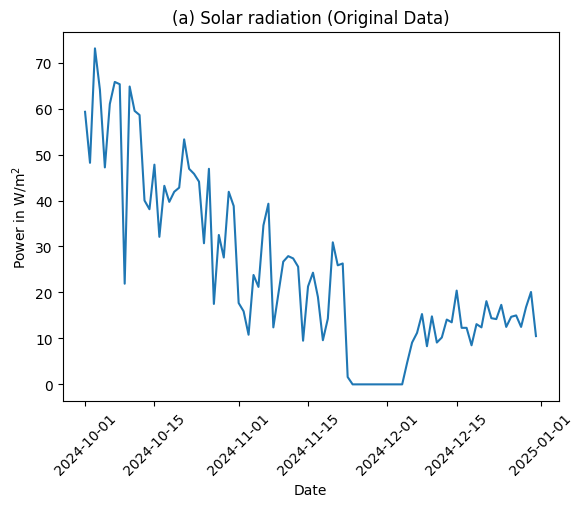

In [23]:
df = df.set_index("datetime")
plt.plot(df['solarradiation'].loc['2024-10-01':'2024-12-31'])
plt.ylabel('Power in W/m$^2$')
plt.xlabel('Date')
plt.xticks(rotation=45)
plt.title('(a) Solar radiation (Original Data)')

In [27]:
# mark only long-zero runs as missing
df.loc[df['solarradiation'] == 0,  'solarradiation'] = np.nan

In [28]:
df['solarradiation'].isnull().sum()

np.int64(12)

In [29]:
# seasonal median imputation by day of the year
df['doy'] = df.index.day_of_year

solar_median = df.groupby('doy')['solarradiation'].median()

In [30]:
#fill in the missing values with DOY median
df['solarradiation']=df.apply(lambda x: solar_median[x['doy']] 
                              if pd.isna(x['solarradiation']) 
                              else x['solarradiation'],axis=1)

In [31]:
df['solarradiation'].isnull().sum()

np.int64(0)

Text(0.5, 1.0, '(b) Solar radiation (DoY median method applied)')

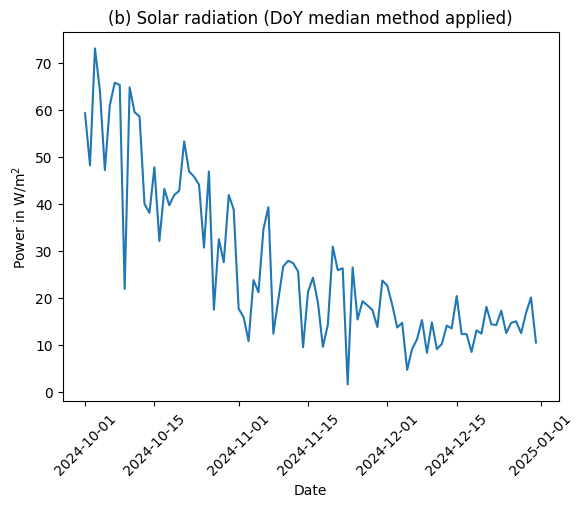

In [32]:
missing_fixed=df['solarradiation'].loc['2024-10-01':'2024-12-31']
plt.plot(missing_fixed)
plt.ylabel('Power in W/m$^2$')
plt.xlabel('Date')
plt.xticks(rotation=45)
plt.title('(b) Solar radiation (DoY median method applied)')

## Summary Statistics 

The describe function is used to generate descriptive statistics for datasets, summarizing key metrics such as mean, standard deviation, and counts of non-missing values. It helps in understanding the distribution and characteristics of the data at a glance.

In [34]:
# For all numeric columns
df.describe()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,precipprob,...,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,moonphase,doy
count,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.00000,3653.000000,3653.000000,3653.000000,3653.000000,...,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000
mean,13.279715,6.716945,10.099261,12.445634,4.379359,8.53712,6.945469,81.790528,1.807310,75.581714,...,27.735149,202.815275,1013.408952,66.762332,18.782727,102.364796,8.821462,3.986039,0.483326,183.150287
std,4.872502,4.479817,4.441397,6.047991,6.023019,5.91795,4.186304,7.070911,3.983873,42.966048,...,9.813167,79.109940,12.088537,17.732543,4.829083,78.440631,6.786054,2.489974,0.288607,105.467566
min,-0.900000,-6.800000,-2.700000,-9.400000,-13.800000,-11.30000,-5.400000,54.300000,0.000000,0.000000,...,8.400000,0.100000,969.200000,8.000000,0.800000,1.600000,0.000000,0.000000,0.000000,1.000000
25%,9.800000,3.200000,6.800000,7.500000,-0.300000,3.80000,3.800000,77.200000,0.001000,100.000000,...,20.400000,153.400000,1005.900000,55.000000,15.900000,33.800000,2.900000,2.000000,0.250000,92.000000
50%,13.100000,6.900000,10.100000,13.100000,4.100000,9.00000,7.100000,82.000000,0.206000,100.000000,...,26.200000,225.300000,1014.500000,67.700000,18.900000,83.500000,7.100000,4.000000,0.500000,183.000000
75%,17.000000,10.200000,13.600000,17.000000,10.200000,13.50000,10.100000,86.700000,1.735000,100.000000,...,33.600000,256.500000,1021.700000,81.700000,21.800000,157.000000,13.600000,6.000000,0.750000,274.000000
max,29.600000,18.600000,23.000000,29.200000,18.600000,22.90000,17.100000,99.400000,63.274000,100.000000,...,77.600000,359.900000,1046.700000,98.900000,37.300000,348.800000,30.200000,10.000000,0.980000,366.000000


## Features Distributions 

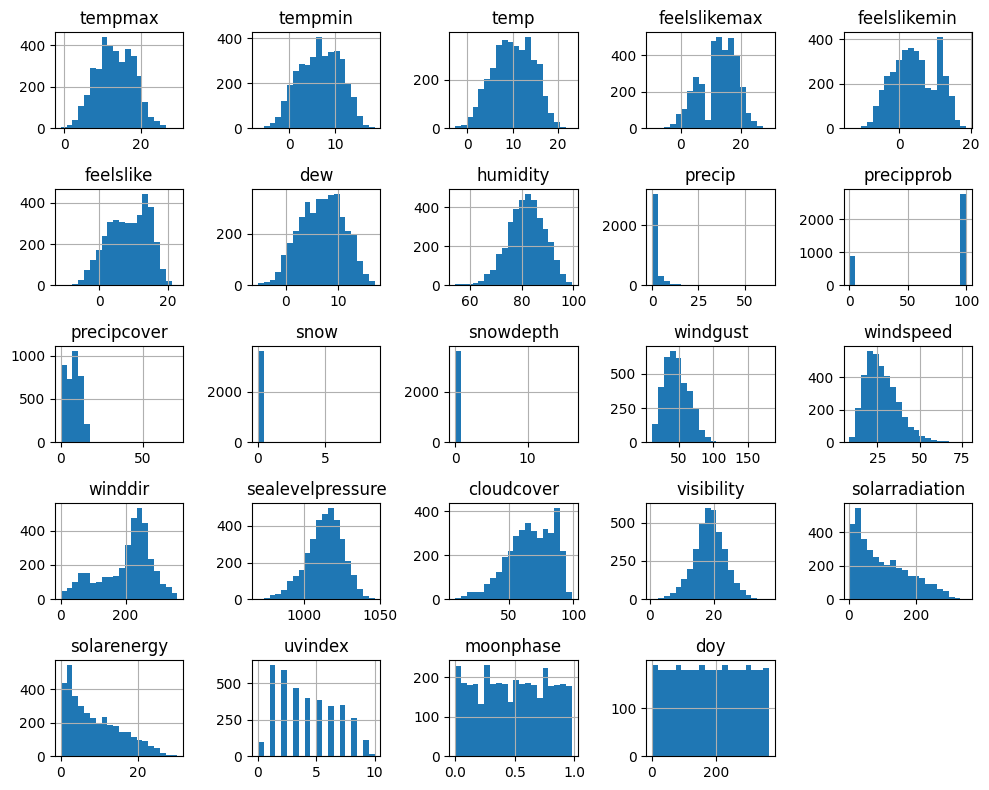

In [35]:
df.hist(bins=20, figsize=(10,8))
plt.tight_layout()
plt.savefig('distributions', dpi=300)
plt.show()


notes:

**Temperature Variables**
- tempmax, tempmin, temp, feelslike, feelslikemin, feelslikemax, show a range between -5 and 25 C. Here is observed two peaks, one at colder temps and one at warmet temps (winter and summer) 

**Humidity variables**
- humidity show normal distribution.

- precip, precipcover, snow, snowdepth, are right skewed,

**Wind variables**

- winddir is spread across 0–360° (wind direction).

- windgust, windspeed are rigth skewed, most days have low winds.

**Solar variables**

- uvindex, solarradiation, solareenergy are right skewed, showing that most days have low sun/solar radiation.

### Saving the new csv

The dataset with 10 years of weather data from Dublin, Ireland has been saved into one csv file.

In [37]:
# Save DataFrame as a CSV
df.to_csv("dbulin 2015-01-01 to 2024-12-31.csv", index=False)